# 16 Anomalieerkennung ohne Labels

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Ziel: auffällig laufende Stationen benennen, ohne vorher ein Fehlerlabel zu vergeben.
- Grund: die Labels tragen nicht. Der überwachte Klassifikator bleibt mit Balanced Accuracy 0,33 bzw. 0,42 unter der Trivialrate 0,50 (`src/ml_classifier.py`, siehe [Negativbefunde](../../docs/negativbefunde.md)).
- Anomalie = Abweichung vom physikalisch erwartbaren Verhalten, die über mehrere Tage anhält. Fünf Detektoren im Vergleich.
- Prüfung ohne Labels: ein brauchbarer Score sinkt nach einer Begehung, bei Kontrollzählern im selben Zeitraum nicht.

**Daten**
- liest: Stundenreihen in `data/processed/real_meters`, Außentemperatur aus dem DWD-Cache, Knotentabelle (Anschlusswerte), Begehungstabelle
- schreibt: `data/processed/anomaliescores.csv`, `anomalie_validierung.csv`, `regelkalibrierung.csv`, `anomaliescores.json`
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/dynamik.py`, `src/tagespanel.py`, `src/anomalie.py` und `src/regelkalibrierung.py`, Tests in den gleichnamigen Dateien unter `tests/`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import anomalie as an
from src import clustervalidierung as cvl
from src import dynamik as dyn
from src import features as ft
from src import jahresvergleich as jv
from src import load_begehungen as lb
from src import load_data as ld
from src import nb00_daten as nb00
from src import regelkalibrierung as rk
from src import tagespanel as tp
from src import weather

from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
SPALTEN = {
    "Energy (kWh)": "energy", "Volume flow (l/h)": "flow",
    "Power (kW)": "power", "Temperature difference (°C)": "dt",
    "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt",
    "Volume (m³)": "volume",
}
t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}")

## 1 Datenbasis

- Stundenreihen aus Notebook 00 (`data/processed/real_meters`): 93 Zähler, 01.11.2021 bis 20.07.2026.
- Fünf Zähler mit ODS-Nachlieferung bis Juli 2026, die übrigen bis 11.07.2025.
- Außentemperatur aus dem DWD-Cache über `src/weather.py` (41.312 Wetterstunden). Sie dient als Einflussgröße im Erwartungswertmodell und als Nenner der Effizienzkennzahl.

In [2]:
#Raster aus NB 00 unverändert, nur leere Zählerstände ergänzt
serien = nb00.lade_serien(METER_DIR, leere_stunden_entfernen=False)
von = min(d.index[0] for d in serien.values() if len(d))
bis = max(d.index[-1] for d in serien.values() if len(d))
t_out = weather.load_outdoor_temperature(von, bis, allow_download=False)
tick(f"{len(serien)} Zaehlerreihen, {von:%Y-%m-%d} bis {bis:%Y-%m-%d}, "
     f"{len(t_out):,} Wetterstunden")

[     1s] 93 Zaehlerreihen, 2021-11-01 bis 2026-07-20, 41,312 Wetterstunden


## 2 Dynamikkennzahlen

- Hypothese: ein festsitzendes oder offenes Ventil zeigt sich als Rücklauf, der kaum auf Lastwechsel reagiert (erste Ableitung, K/h). Ein defekter Regler zeigt sich als unruhiges Signal (zweite Ableitung).
- Dazu: Kopplung von Rücklauf und Vorlauf, Anteil praktisch stehender Rücklaufstunden (`rt_traege_anteil`) und Reaktionszeit auf Lastwechsel.
- Differenzen über einen fehlenden Zeitschritt hinweg werden verworfen.
- Beispiel unten: Zähler 53198226, 32.342 Stunden, Tagesdynamik an 910 von 1.349 Tagen.

In [3]:
beispiel = sorted(serien)[0]
reihe = serien[beispiel]
abl = dyn.ableitungen(reihe)
print(f"Zaehler {beispiel}: {len(reihe):,} Stunden")
print(abl[[c for c in abl.columns if c.startswith("rt_d")]].describe().round(3))
tag = dyn.tagesdynamik(reihe)
belegt = tag.dropna(subset=["rt_d1_abs_mean"])
print(f"\nTagesdynamik: {len(belegt)} von {len(tag)} Tagen belegt")
print(belegt.head(3).to_string(index=False))
print("\nSpalten:", list(tag.columns))

Zaehler 53198226: 32,342 Stunden
           rt_d1      rt_d2
count  21801.000  21785.000
mean       0.001      0.000
std        8.881     15.281
min      -49.400    -67.000
25%       -2.900     -5.400
50%        0.000      0.000
75%        2.700      5.100
max       45.100     77.000

Tagesdynamik: 910 von 1349 Tagen belegt
     datum  rt_d1_abs_mean  rt_d1_abs_p95  rt_d2_abs_mean  rt_d2_abs_p95  rt_spanne_k  rt_traege_anteil  rt_vl_kopplung  n_dyn  n_last  reaktionszeit_h  n_lastwechsel
2022-11-13        2.525000          7.115        4.813043         12.040          9.5               0.0        0.620528     24       6              1.0              5
2022-11-14        5.841667         26.255        9.770833         30.335         37.0               0.0       -0.184940     24      14              2.0              7
2022-11-15        8.237500         33.485       15.695833         53.130         37.0               0.0       -0.347567     24      11              1.0              9

Spalt

## 3 Stundencluster als Zustandsanteil

- Die fünf Betriebszustände aus Notebook 09 gehen als Zeitanteil je Station und Tag ins Panel ein (1.676.633 Stunden, 92 Zähler).
- Der Cluster mit Verdacht auf hydraulischen Kurzschluss (viel Wasser, kaum Auskühlung) wird über das Zentroidprofil bestimmt: hoher Durchfluss, kleinste Spreizung (Spreizung = Vorlauf minus Rücklauf).
- Die Clusternummer selbst hängt vom Zufallsstartwert ab und taugt dafür nicht.
- Hier ist es Cluster 1: Spreizung 4,2 K, Rücklauf 71 °C, 13,1 % der Stunden.

In [4]:
panel_h, ausschluss = cvl.lade_stundenpanel(METER_DIR)
panel_h = cvl.mit_kontext(panel_h, t_out)
X = StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES])
labels = cvl.fit_minibatch_kmeans(X, 5, n_init=10)
panel_h["cluster"] = labels
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(),
                               labels, cvl.BETRIEBS_FEATURES)
tick(f"Stundencluster: {len(panel_h):,} Stunden, "
     f"{panel_h['Zählernummer'].nunique()} Zaehler")
print(profil_h.round(2).to_string())

kandidat = profil_h[profil_h["flow_norm"] > 0.3]
KURZ = int(kandidat["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
print(f"\nKurzschlussverdacht ist Cluster {KURZ}, Spalte {ANTEIL}")

[     3s] Stundencluster: 1,676,633 Stunden, 92 Zaehler
         power_norm  flow_norm     dt     vl     rt  n_stunden  anteil_%
cluster                                                                 
0              0.07       0.09  11.90  65.76  53.82     416380      24.8
1              0.21       0.76   4.15  75.17  70.98     219361      13.1
2              0.32       0.21  33.76  67.23  33.42     417773      24.9
3              0.00       0.01   3.34  35.16  31.79     322005      19.2
4              0.89       0.84  23.26  73.53  50.23     301114      18.0

Kurzschlussverdacht ist Cluster 1, Spalte anteil_c1


## 4 Tagespanel

- Station × Tag als gemeinsame Basis aller Detektoren: Tageswerte der Messgrößen, Zustandsanteile, Dynamik, Tagesmitteltemperatur, Heizgradstunden.
- 88.792 Stationstage: 99,8 % mit genug Messstunden, 20 % ohne Laststunde, Dynamik für 78,7 %, Zustandsanteile für 95,7 %.
- `genug_stunden` markiert die auswertbaren Tage. Nichts wird stillschweigend verworfen.

In [5]:
panel = tp.baue_tagespanel(serien, stundencluster=panel_h, t_out=t_out)
tick(f"Tagespanel {panel.shape}, {panel['meter'].nunique()} Zaehler, "
     f"{panel['datum'].min():%Y-%m-%d} bis {panel['datum'].max():%Y-%m-%d}")
bilanz = tp.panelbilanz(panel)
print(bilanz.to_string(index=False))

[    47s] Tagespanel (88792, 43), 93 Zaehler, 2021-11-01 bis 2026-07-20
                 bedingung  tage   anteil
       Stationstage gesamt 88792 1.000000
         genug Messstunden 88606 0.997905
  Tag ohne jede Laststunde 18072 0.203532
         Dynamik gerechnet 69916 0.787413
 Zustandsanteile vorhanden 84976 0.957023
Aussentemperatur vorhanden 88700 0.998964


In [6]:
print("Spalten des Panels:")
for s in sorted(panel.columns):
    print("  ", s)

Spalten des Panels:
   anteil_c0
   anteil_c1
   anteil_c2
   anteil_c3
   anteil_c4
   datum
   dt_mean
   dt_mean_loaded
   energie_kwh
   flow_mean
   flow_median
   genug_stunden
   heizgradstunden
   last_anteil
   meter
   monat
   n_dyn
   n_last
   n_lastwechsel
   n_stunden
   n_stunden_basis
   n_stunden_cluster
   performance
   performance_gueltig
   power_max
   power_mean
   reaktionszeit_h
   rt_d1_abs_mean
   rt_d1_abs_p95
   rt_d2_abs_mean
   rt_d2_abs_p95
   rt_mean
   rt_mean_loaded
   rt_median
   rt_p95
   rt_spanne_k
   rt_traege_anteil
   rt_vl_kopplung
   season
   spreizung_k
   t_out_tag
   vl_mean
   volumen_m3


## 5 Erwartungswertmodell

- Zielgröße: Tagesmedian des Rücklaufs bei gegebener Außentemperatur und Last. Liegt der gemessene Rücklauf darüber, ist das das Anomaliesignal (Residuum = gemessen minus erwartet).
- Netzweit, eine Regression für alle Stationen: „Wer kühlt im Netzvergleich schlecht aus?“ Schwäche: bauartbedingte Unterschiede fallen auf, ohne dass etwas defekt ist.
- Stationseigen, eine Regression je Station: „Wann hat sich eine Station verschlechtert?“ Schwäche: eine von Anfang an schlecht laufende Station wird zur eigenen Norm.

In [7]:
panel, info_netz = an.erwartungsmodell_netz(panel)
print("Netzweites Modell")
print(f"  Zielgroesse      {an.ZIEL}")
print(f"  Praediktoren     {list(an.PRAEDIKTOREN)}")
print(f"  Tage im Fit      {info_netz['n_tage']:,}")
print(f"  Stationen        {info_netz['n_stationen']}")
print(f"  r2               {info_netz['r2']:.3f}")
for name in info_netz["beta"]:
    print(f"  beta {name:<16} {info_netz['beta'][name]:+.3f}"
          f"  se {info_netz['se'][name]:.3f}  p {info_netz['p'][name]:.4f}")

panel, bilanz_station = an.erwartungsmodell_station(panel)
print(f"\nStationseigenes Modell: {int(bilanz_station['geschaetzt'].sum())} "
      f"von {len(bilanz_station)} Stationen geschaetzt")
nicht = bilanz_station[~bilanz_station["geschaetzt"]]
if len(nicht):
    print("nicht geschaetzt:")
    print(nicht["grund"].value_counts().to_string())
tick("Erwartungswertmodelle")

Netzweites Modell
  Zielgroesse      rt_median
  Praediktoren     ['t_out_tag', 'last_anteil', 'power_mean']
  Tage im Fit      85,676
  Stationen        93
  r2               0.035
  beta achsenabschnitt  +41.906  se 2.311  p 0.0000
  beta t_out_tag        +0.186  se 0.083  p 0.0273
  beta last_anteil      +3.617  se 2.119  p 0.0913
  beta power_mean       +0.091  se 0.019  p 0.0000

Stationseigenes Modell: 93 von 93 Stationen geschaetzt
[    47s] Erwartungswertmodelle


- Netzmodell: R² = 0,035 auf 85.676 Tagen. Mittlere Leistung (p < 0,001) und Außentemperatur (p = 0,027) tragen, der Lastanteil nicht (p = 0,09).
- Belastbar ist damit die Rangfolge der Stationen, nicht der Absolutwert.
- Stationseigenes Modell für alle 93 Stationen. Sein Residuum mittelt per Konstruktion auf null und sagt nur in Zeitfenstern etwas aus.

## 6 Weitere Detektoren

- Isolation Forest auf dem Tagespanel (sucht seltene Tage, die sich leicht von den übrigen abtrennen lassen): 8 Merkmale, 63.570 Tage, 92 Stationen, contamination 0,05.
- Zustandsanteil: Zeitanteil im Kurzschlussverdacht. 18 von 92 Stationen liegen im Mittel über 20 %.
- Dynamikscore: Summe robuster z-Werte aus Kopplung Rücklauf–Vorlauf und zweiter Ableitung. `rt_traege_anteil` fällt raus, weil er über alle Tage keine Streuung hat. Er prüft die Hypothese aus Abschnitt 2.

In [8]:
IF_MERKMALE = ["rt_median", "dt_mean_loaded", "t_out_tag", "last_anteil",
               "power_mean", "flow_median", "rt_d1_abs_mean", "rt_vl_kopplung"]
panel, info_if = an.score_isolation_forest(panel, IF_MERKMALE)
print(f"Isolation Forest: {info_if['n_tage']:,} Tage, "
      f"{len(info_if['merkmale'])} Merkmale, contamination "
      f"{info_if['contamination']}")

panel = an.score_zustand(panel, [ANTEIL])
zustand_je_station = panel.groupby("meter")[ANTEIL].mean().dropna()
print(f"Zeitanteil im Kurzschlussverdacht: {int((zustand_je_station > 0.2).sum())} "
      f"von {len(zustand_je_station)} Stationen ueber 20 Prozent")
panel, info_dyn = an.score_dynamik(panel)
print(f"Dynamikscore aus {info_dyn['benutzt']}")
for spalte, grund in info_dyn["verworfen"].items():
    print(f"  verworfen: {spalte} - {grund}")

DETEKTOREN = [f"score_{n}" for n in (an.D_RESID_NETZ, an.D_RESID_STATION,
                                     an.D_IFOREST, an.D_ZUSTAND, an.D_DYNAMIK)]
belegung = pd.DataFrame([
    {"detektor": d, "belegte_stationstage": int(panel[d].notna().sum()),
     "stationen": int(panel.loc[panel[d].notna(), "meter"].nunique())}
    for d in DETEKTOREN])
print()
print(belegung.to_string(index=False))
tick("Detektoren gebaut")

Isolation Forest: 63,570 Tage, 8 Merkmale, contamination 0.05
Zeitanteil im Kurzschlussverdacht: 18 von 92 Stationen ueber 20 Prozent
Dynamikscore aus ['rt_vl_kopplung', 'rt_d2_abs_mean']
  verworfen: rt_traege_anteil - MAD ueber alle Stationstage null, keine Streuung zu standardisieren

              detektor  belegte_stationstage  stationen
   score_residuum_netz                 85676         93
score_residuum_station                 85676         93
score_isolation_forest                 63570         92
  score_zustandsanteil                 84976         92
         score_dynamik                 69915         93
[    49s] Detektoren gebaut


- `rt_traege_anteil` fällt aus dem Dynamikscore. Auf Tagesebene ist er fast immer null, die MAD (Median der absoluten Abweichungen vom Median) über alle Stationstage ist null.
- Bei stündlicher Messung und 0,1 K Auflösung ist ein stehender Rücklauf kaum zu beobachten.
- Die erhoffte Ventilkennzahl trägt im Tagespanel keine Information.

## 7 Übereinstimmung der Detektoren

- Vergleich auf Stationsebene: Spearman-Rangkorrelation und Jaccard-Überlappung der jeweils 15 höchsten Stationen.
- Netzresiduum und Zustandsanteil sind sich am ähnlichsten (Spearman 0,69, Jaccard 0,67). Der Isolation Forest liegt dazwischen (Spearman 0,58 zum Netzresiduum, 0,49 zum Zustandsanteil).
- Der Dynamikscore korreliert mit allen negativ (−0,08 bis −0,49), Top-15-Überschneidung höchstens 0,03.
- Stationseigenes Residuum: Stationsmittel per Konstruktion null. Die Spearman −0,04 zum Netzresiduum ordnet nur Rundungsrauschen.

In [9]:
schwellen = {}
for d in DETEKTOREN:
    panel, s = an.persistente_tage(panel, d)
    schwellen[d] = s

scores = an.scoretabelle(panel, DETEKTOREN)
rang, jacc = an.uebereinstimmung(scores, DETEKTOREN, top_n=15)
print("Spearman ueber die Stationen:")
print(rang.round(2).to_string())
print("\nJaccard der Top 15:")
print(jacc.round(2).to_string())

Spearman ueber die Stationen:
                        score_residuum_netz  score_residuum_station  score_isolation_forest  score_zustandsanteil  score_dynamik
score_residuum_netz                    1.00                   -0.04                    0.58                  0.69          -0.31
score_residuum_station                -0.04                    1.00                    0.19                  0.07          -0.20
score_isolation_forest                 0.58                    0.19                    1.00                  0.49          -0.49
score_zustandsanteil                   0.69                    0.07                    0.49                  1.00          -0.08
score_dynamik                         -0.31                   -0.20                   -0.49                 -0.08           1.00

Jaccard der Top 15:
                        score_residuum_netz  score_residuum_station  score_isolation_forest  score_zustandsanteil  score_dynamik
score_residuum_netz                    1.00   

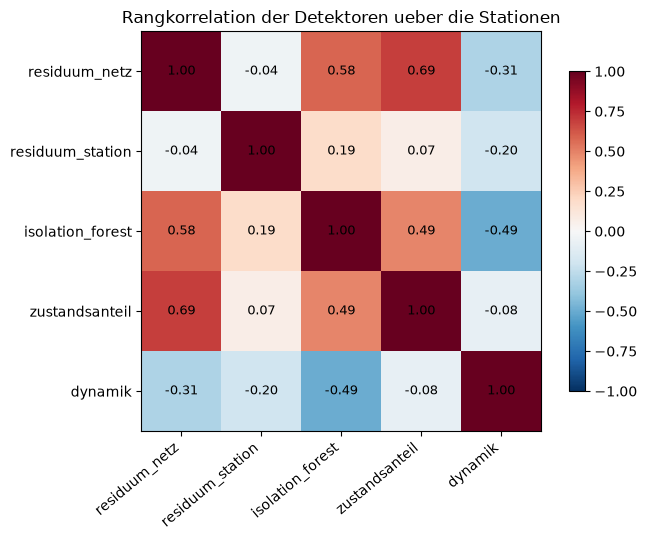

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
bild = ax.imshow(rang.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
kurz = [n.replace("score_", "") for n in rang.columns]
ax.set_xticks(range(len(kurz)), kurz, rotation=40, ha="right")
ax.set_yticks(range(len(kurz)), kurz)
for i in range(len(kurz)):
    for j in range(len(kurz)):
        ax.text(j, i, f"{rang.to_numpy()[i, j]:.2f}", ha="center",
                va="center", fontsize=9)
ax.set_title("Rangkorrelation der Detektoren ueber die Stationen")
fig.colorbar(bild, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 8 Persistenz

- Persistent auffällig heißt: im 14-Tage-Fenster mindestens `min_tage` Tage (Standard 7) über der Tagesschwelle.
- Tagesschwelle: 90. Perzentil aller Stationstage (Netzresiduum 22,1 K).
- Netzresiduum ohne Filter: 43 Stationen mit Treffer, 13,5 % der Stationstage auffällig.
- Mit 7 von 14 Tagen: 27 Stationen, 9,8 % der Stationstage, 19 Stationen an mehr als 10 % ihrer Tage.

In [11]:
netz = f"score_{an.D_RESID_NETZ}"
zeilen = []
for min_tage in (1, 3, 5, 7, 10, 14):
    p2, _ = an.persistente_tage(panel, netz, schwelle=schwellen[netz],
                                fenster=14, min_tage=min_tage)
    tab = an.stationsscore(p2, netz)
    zeilen.append({"min_tage": min_tage,
                   "stationen_mit_treffer": int((tab["anteil_persistent"] > 0).sum()),
                   "stationen_ueber_10_prozent": int((tab["anteil_persistent"] > 0.10).sum()),
                   "anteil_persistenter_tage": float(p2[f"persistent_{netz}"].mean())})
persistenz = pd.DataFrame(zeilen)
print(f"Tagesschwellen (90. Perzentil): "
      + ", ".join(f"{k.replace('score_', '')} {v:.3f}" for k, v in schwellen.items()))
print()
print(persistenz.round(3).to_string(index=False))

Tagesschwellen (90. Perzentil): residuum_netz 22.143, residuum_station 7.917, isolation_forest 0.505, zustandsanteil 0.708, dynamik 1.138

 min_tage  stationen_mit_treffer  stationen_ueber_10_prozent  anteil_persistenter_tage
        1                     43                          23                     0.135
        3                     31                          22                     0.114
        5                     27                          20                     0.106
        7                     27                          19                     0.098
       10                     21                          16                     0.087
       14                     20                          13                     0.060


## 9 Validierung über die Begehungen

- Je Begehung ein Fensterpaar im Kernwinter vor und nach dem Eingriff. Dieselben Fenster gelten für Kontrollzähler ohne Begehung (wie in Notebook 04).
- 58 Begehungen auf 56 Zählern, 42 Kontrollzähler. Auswertbar sind n = 43 (Isolation Forest 42).
- Gepaarter Wilcoxon-Test und Diff-in-Diff gegen die Kontrollgruppe (Diff-in-Diff = Änderung bei den begangenen Zählern minus Änderung bei den Kontrollen). Bestanden heißt: Diff-in-Diff negativ und p < 0,05.
- Zum Vergleich die Rohgrößen `rt_median` und `rt_mean_loaded` (Mittel nur über Laststunden).

In [12]:
zaehler = set(panel["meter"].unique())
begehungen = (lb.begehungen_mit_zaehler(available=zaehler)
              .dropna(subset=["meter", "datum"]))
begehungen["meter"] = begehungen["meter"].astype(int)
kontroll = sorted(zaehler - set(begehungen["meter"]))
cache = {}


def fenster(datum):
    key = pd.Timestamp(datum).normalize()
    if key not in cache:
        cache[key] = jv.winterfenster(key, jv.WINTER_KERN)
    return cache[key]


print(f"{len(begehungen)} Begehungen auf {begehungen['meter'].nunique()} "
      f"Zaehlern, {len(kontroll)} Kontrollzaehler")

zeilen = []
for d in DETEKTOREN + ["rt_median", "rt_mean_loaded"]:
    kennzahlen = (("score_mittel", "anteil_auffaellig")
                  if f"auffaellig_{d}" in panel.columns else ("score_mittel",))
    did = an.diff_in_diff(panel, d, begehungen, kontroll, fenster,
                          kennzahlen=kennzahlen)
    if len(did) == 0:
        print(f"{d}: kein auswertbares Fensterpaar")
        continue
    zeilen.append({"detektor": d, **an.validierungsbilanz(did, "score_mittel")})
validierung = pd.DataFrame(zeilen)
print()
print(validierung.round(4).to_string(index=False))
tick("Begehungsvalidierung")

58 Begehungen auf 56 Zaehlern, 42 Kontrollzaehler


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)



              detektor     kennzahl  n  median_station  p_station  median_did  p_did  bestanden
   score_residuum_netz score_mittel 43         -0.7041     0.1110     -1.3436 0.0174       True
score_residuum_station score_mittel 43         -0.2775     0.2614     -0.8553 0.0413       True
score_isolation_forest score_mittel 42          0.0044     0.1351      0.0012 0.6214      False
  score_zustandsanteil score_mittel 43          0.0000     0.7588      0.0000 0.7588      False
         score_dynamik score_mittel 43          0.0033     0.7720      0.0161 0.8943      False
             rt_median score_mittel 43         -1.1963     0.0477     -1.7422 0.0091       True
        rt_mean_loaded score_mittel 42         -0.6232     0.1109     -0.6943 0.0926      False
[    52s] Begehungsvalidierung


- Bestanden: Netzresiduum (Diff-in-Diff −1,34, p = 0,017) und stationseigenes Residuum (−0,86, p = 0,041).
- Nicht bestanden: Isolation Forest (+0,001, p = 0,62, gepaart eher ein Anstieg), Zustandsanteil (Median 0, p = 0,76), Dynamikscore (+0,02, p = 0,89).
- `rt_median` allein liefert dasselbe (−1,74 K, p = 0,009), `rt_mean_loaded` nicht (p = 0,09). Der Effekt der Residuen kommt also großteils aus der Zielgröße.
- Einschränkung: alle auswertbaren Begehungen teilen dasselbe Fensterpaar im Kernwinter. Der Diff-in-Diff gleicht damit die Witterung aus, aber keinen begehungsspezifischen Zeiteffekt.

## 10 Plausibilisierung über den Energieeinsatz

- Frage: kostet eine hohe Punktzahl Energie?
- Kennzahl: Energie je Heizgradstunde (kWh/Kh) je Station. Oberstes Quintil je Detektor gegen den Rest, Mann-Whitney-Test.
- Gleicht Winterhärte und Länge der Historie aus, nicht die Gebäudegröße.

In [13]:
eff = an.effizienz_je_station(panel)
tab = scores.merge(eff[["meter", "energie_je_kh"]], on="meter", how="left")
zeilen = []
for d in DETEKTOREN:
    s = tab[[d, "energie_je_kh"]].dropna()
    grenze = s[d].quantile(0.80)
    r = an.gruppenvergleich(s[s[d] >= grenze]["energie_je_kh"],
                            s[s[d] < grenze]["energie_je_kh"])
    zeilen.append({"detektor": d, **r})
effizienz = pd.DataFrame(zeilen)
print("kWh je Heizgradstunde, oberstes Quintil gegen Rest")
print(effizienz.round(4).to_string(index=False))

kWh je Heizgradstunde, oberstes Quintil gegen Rest
              detektor  n_hoch  n_niedrig  median_hoch  median_niedrig      p
   score_residuum_netz      19         74       0.2979          0.2559 0.3529
score_residuum_station      19         74       0.4570          0.2668 0.0248
score_isolation_forest      19         73       0.3095          0.2366 0.0217
  score_zustandsanteil      19         73       0.3101          0.2366 0.0399
         score_dynamik      19         74       0.1852          0.3055 0.0008


- Isolation Forest 0,31 gegen 0,24 kWh/Kh (p = 0,022), Zustandsanteil 0,31 gegen 0,24 (p = 0,040). Netzresiduum nur in derselben Richtung (0,30 gegen 0,26, p = 0,35).
- Stationseigenes Residuum (p = 0,025) ist ein Artefakt: das Quintil sortiert Stationsmittel, die per Konstruktion null sind.
- Dynamikscore umgekehrt: 0,19 gegen 0,31 (p < 0,001). Er bildet eher Betriebsintensität oder Stationsgröße ab als Fehlverhalten.

## 11 Benennbares Muster je Station

- Jede Station bekommt ein Muster: woran hängt die Auffälligkeit im Messsignal? Beschreibung, keine Diagnose.
- Regeln auf Quantilen der Stationsmediane (p20/p80) statt auf festen Schwellen aus der Literatur.
- Ergebnis: 50 ohne eindeutiges Muster, 16 unruhige Regelung, 12 Rücklauf über Erwartung ohne weiteres Merkmal, 7 Ventilverdacht, 5 Kurzschlussverdacht, 3 Durchfluss ohne nennenswerte Abnahme.
- Von den 19 persistent auffälligen Stationen: 9 „Rücklauf über Erwartung“, 5 ohne Muster. Die Ventilregel greift knapp über der Auflösungsgrenze, nur eine dieser Stationen (66761022) ist persistent auffällig. „Unruhige Regelung“ hängt am durchgefallenen Dynamikscore.

In [14]:
PROFILSPALTEN = ["rt_vl_kopplung", "dt_mean_loaded", "rt_traege_anteil",
                 "rt_d1_abs_mean", "rt_d2_abs_mean", "flow_median",
                 "last_anteil", netz]
profil = an.stationsprofil(panel, PROFILSPALTEN)
muster = an.muster_je_station(profil)
print(muster["muster"].value_counts().to_string())

muster
kein eindeutiges Muster                                                50
unruhige Regelung                                                      16
Ruecklauf ueber Erwartung ohne weiteres Merkmal                        12
Ruecklauf reagiert kaum, Verdacht festsitzendes oder offenes Ventil     7
Ruecklauf folgt dem Vorlauf, Verdacht hydraulischer Kurzschluss         5
Durchfluss ohne nennenswerte Abnahme                                    3


In [15]:
stat = an.stationsscore(panel, netz)
treffer = stat[stat["anteil_persistent"] > 0.10].merge(muster, on="meter")
print(f"Stationen mit persistentem Befund ueber 10 Prozent der Tage: "
      f"{len(treffer)} von {panel['meter'].nunique()}")
print()
print(treffer.sort_values("anteil_persistent", ascending=False)
      [["meter", "score_mittel", "anteil_persistent", "max_lauf", "muster"]]
      .head(21).round(3).to_string(index=False))

Stationen mit persistentem Befund ueber 10 Prozent der Tage: 19 von 93

   meter  score_mittel  anteil_persistent  max_lauf                                                              muster
80912182        28.007              0.967       234                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
72167793        24.496              0.889        55                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
72167782        27.185              0.769       303                                Durchfluss ohne nennenswerte Abnahme
68956351        21.725              0.765       288                                Durchfluss ohne nennenswerte Abnahme
72135480        24.636              0.732       265                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
68956360        12.512              0.480       195                     Ruecklauf ueber Erwartung ohne weiteres Merkmal
72167783         4.783              0.425       199                     Ruecklauf ueber 

## 12 Nachkalibrierung der Regel-Baseline

- Die Regel-Baseline in `src/fault_detection.py` passt nicht zu den echten Daten. Einzelne Regeln treffen fast alle oder keine Station.
- Neue Schwelle je Regel: das Quantil, das rund 15 % der Stationen trifft. Die 15 % sind gesetzt, angelehnt an 19 von 93 persistent auffälligen Stationen.
- `peak_load_share` braucht den Anschlusswert aus der Knotentabelle (85 von 93 Stationen).

In [16]:
nodes = ld.load_logical_nodes()
features = nb00.stationsfeatures(METER_DIR, nodes_df=nodes)
features = features.rename(columns={"Zählernummer": "meter"})
print(f"Stationsfeatures {features.shape}, Anschlusswert fuer "
      f"{int(features['anschlusswert_kw'].notna().sum())} von {len(features)} "
      f"Stationen")

neu, bilanz_rk = rk.kalibriere(features)
vn = rk.vorher_nachher(features, neu)
print()
print(vn.round(3).to_string(index=False))

Stationsfeatures (93, 24), Anschlusswert fuer 85 von 93 Stationen

                    schwelle             fehler                                     beschreibung  n_stationen  schwelle_alt  treffer_alt  anteil_alt  schwelle_neu  treffer_neu  anteil_neu
              rt_mean_winter          excess_rt                      Ruecklauf im Winter zu warm           93         48.00           34       0.366        56.406           14       0.151
    rt_above_50_share_loaded          excess_rt   Anteil Laststunden mit Ruecklauf ueber 50 Grad           93          0.30           56       0.602         0.798           14       0.151
        summer_flow_baseline    continuous_flow                       Mediandurchfluss im Sommer           93         25.00           27       0.290        76.400           14       0.151
     summer_idle_flow_median    continuous_flow           Durchfluss in lastfreien Sommerstunden           93         15.00           20       0.215        35.400           14      

In [17]:
print("Labelverteilung mit den alten Schwellen")
print(rk.labelverteilung(features).to_string())
print("\nLabelverteilung mit den kalibrierten Schwellen")
print(rk.labelverteilung(features, neu).to_string())
tick("Regelkalibrierung")

Labelverteilung mit den alten Schwellen
predicted_fault
control_hysteresis    44
excess_rt             34
fouled_filter         11
continuous_flow        4

Labelverteilung mit den kalibrierten Schwellen
predicted_fault
healthy               38
excess_rt             17
control_hysteresis    13
fouled_filter         10
oversized_contract     7
continuous_flow        6
low_spreading          2
[    54s] Regelkalibrierung


## 13 Was nicht getragen hat

- Isolation Forest: findet teils dieselben Stationen wie das Netzresiduum, reagiert aber nicht auf den Eingriff. Mögliche Lesart, nicht geprüft: seltene Punkte sind eher Stillstands- oder Spitzentage als Tage mit schlechter Auskühlung.
- Zustandsanteil: gute beschreibende Kennzahl, aber kein Maß für Wirkung.
- Dynamikscore: Ventil- und Reglerhypothese auf diesen Daten nicht bestätigt. Wahrscheinlich ist die zweite Ableitung bei 0,1 K Auflösung großteils Quantisierungsrauschen (Rauschen durch die grobe Auflösung).
- Alte Regelschwellen: `flow_short_cycle_power` 0,07 trifft 83 von 93 (kalibriert 0,289). `rt_above_50_share_loaded` 0,30 trifft 56 von 93 (kalibriert 0,798). `peak_load_share` 0,40 trifft keine (kalibriert 1,274, 13 von 85).

## 14 Export

- `data/processed/anomaliescores.csv`: Stationsscores mit Persistenz, Muster und Energie je Heizgradstunde.
- Dazu `anomalie_validierung.csv`, `regelkalibrierung.csv` und der Lauf-Kontext `anomaliescores.json`.
- Nur Zählernummern, keine Adressen.

In [18]:
AUS = ROOT / "data" / "processed"
AUS.mkdir(parents=True, exist_ok=True)

export = (scores.merge(stat[["meter", "anteil_auffaellig",
                             "anteil_persistent", "max_lauf"]],
                       on="meter", how="left")
                .merge(muster, on="meter", how="left")
                .merge(eff[["meter", "energie_je_kh"]], on="meter", how="left"))
export.to_csv(AUS / "anomaliescores.csv", index=False)
validierung.to_csv(AUS / "anomalie_validierung.csv", index=False)
vn.to_csv(AUS / "regelkalibrierung.csv", index=False)

kontext = {
    "stand": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "zaehler": int(panel["meter"].nunique()),
    "stationstage": int(len(panel)),
    "zeitraum": [str(panel["datum"].min().date()), str(panel["datum"].max().date())],
    "zielgroesse": an.ZIEL,
    "praediktoren": list(an.PRAEDIKTOREN),
    "seed": an.SEED,
    "kurzschlusscluster": KURZ,
    "r2_netzmodell": float(info_netz["r2"]),
    "persistenz": {"fenster": an.PERSISTENZ_FENSTER,
                   "min_tage": an.PERSISTENZ_MIN_TAGE,
                   "schwellenquantil": an.SCHWELLENQUANTIL},
    "tagesschwellen": {k: float(v) for k, v in schwellen.items()},
    "validierung": validierung.set_index("detektor").to_dict(orient="index"),
    "zielanteil_regeln": rk.ZIELANTEIL,
    "stationen_persistent_ueber_10_prozent": int(len(treffer)),
}
(AUS / "anomaliescores.json").write_text(
    json.dumps(kontext, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"{len(export)} Stationen exportiert nach data/processed/")
print(export.head(5).round(3).to_string(index=False))

93 Stationen exportiert nach data/processed/
   meter  score_residuum_netz  score_residuum_station  score_isolation_forest  score_zustandsanteil  score_dynamik  anteil_auffaellig  anteil_persistent  max_lauf                  muster                   begruendung  energie_je_kh
53198226                5.196                    -0.0                   0.479                 0.004         -1.098              0.001               0.00         1 kein eindeutiges Muster                                        0.568
58177363               -9.596                    -0.0                   0.445                 0.000         -1.081              0.000               0.00         0 kein eindeutiges Muster                                        0.168
58177384                1.274                     0.0                   0.427                 0.015         -0.114              0.000               0.00         0 kein eindeutiges Muster                                        0.312
58202380               -2.0

## Zusammenfassung & Bewertung

**Ergebnis**
- Netzresiduum und stationseigenes Residuum bestehen die Begehungsvalidierung (n = 43, 42 Kontrollzähler), drei Detektoren nicht.
- Das Netzresiduum taugt für Ranglisten, das stationseigene Residuum nur für Zeitfenster.
- 19 von 93 Stationen sind an mehr als 10 % ihrer Tage persistent auffällig.

**Belastbar**
- Die Trefferliste ist plausibel: 68956351 (Ventil drei Jahre offen, Reparatur nicht in der Begehungstabelle) steht auf Rang 4, persistenter Anteil 0,765. Ein Hinweis, keine Validierung.
- Auffällige Stationen brauchen mehr Energie je Heizgradstunde (Isolation Forest, Zustandsanteil; beim Netzresiduum nicht gesichert).
- Nach der Kalibrierung trifft jede Regel rund 15 % statt zwischen 0 und 89 %. Die Labelverteilung wechselt von 44 × `control_hysteresis` und keinem `healthy` zu 38 × `healthy` und sechs Fehlerbildern. Das macht die Regeln bewertbar, nicht richtig.

**Schwach**
- Die Residuen bringen gegenüber dem rohen Tagesmedian des Rücklaufs keinen Gewinn in der Validierung.
- Der Diff-in-Diff ist eher ein verschobener gepaarter Test. R² des Netzmodells nur 0,035. Energie je Heizgradstunde ist nicht nach Gebäudegröße bereinigt.

**Offen**
- Die Zielquote von 15 % ist gesetzt, nicht entschieden.
- `peak_load_share` über 1,0: echte Lastspitzen oder zu niedrige Anschlusswerte in der Knotentabelle?
- Geprüft ist nur die Wirkung der Begehung auf den Rücklauf. Ob eine auffällige Station den zugeordneten Fehler hat, lässt sich mit 57 Freitexten nicht zeigen.